# KNMI radar precipitation per polder, and whether Pastas gets better with it

**Local notebook** (not a Databricks job; the cluster has no internet egress).

**Why.** Every model is driven by KNMI 249 Berkhout, 5 to 25 km from the dikes. A convective shower can fall on a polder and miss Berkhout,
or the reverse. Radar sees the polder itself.

**The data.** The KNMI Data Platform dataset `rad_nl25_rac_mfbs_24h` 2.0 is the *climatological* radar product: 24-hour sums on a 1 km grid,
adjusted with both KNMI gauge networks, in HDF5, under CC BY 4.0.
* It comes as one zip per year (600–900 MB) holding a rolling 24-hour sum every hour.
* We read only the sum ending at 08:00 UTC: the same 08–08 day as the KNMI neerslagstations, labelled by the day it ends.
* The models move it one day back, as with the neerslagstations (variant `localP`).
* The product follows about a month behind real time, because of the gauge adjustment.

**One point per polder:** the radar pixel at the centroid of the polder's piezometers (`stresses.polder_points`).
That gives one series each for Beemster, Purmer and Heerhugowaard.

**Key.** `KNMI_API_KEY` is used if it is set. Otherwise the code uses the *anonymous* key that KNMI publishes for everyone on
https://developer.dataplatform.knmi.nl/open-data-api. That key is shared, rate-limited, and valid until 2027-08-01.
Two calls per year are enough. While the key is rate-limited the download waits and retries.

**Evaporation** stays Berkhout Makkink. The radar product has no evaporation, and Makkink varies little over 20 km.
The earlier test with station-weighted Makkink (`localPE`) gained nothing.

**Code:** `research/accepted/radar.py` (download, grid lookup, cache), and the variant `radar` in `research/accepted/variants.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PASTAS = Path.cwd().resolve()
while not (PASTAS / "research").is_dir():
    PASTAS = PASTAS.parent
for p in (PASTAS, PASTAS / "src"):
    sys.path.insert(0, str(p))
from research import data
from research.accepted import radar, stresses

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
POINTS = {p: stresses.polder_points()[p] for p in radar.POLDERS}
POINTS

{'Beemster': (52.5717, 4.915),
 'Purmer': (52.4932, 4.9935),
 'Heerhugowaard': (52.6755, 4.8495)}

## Where the radar is read
The piezometers of each polder, the radar point (the centroid), the pumping stations, and KNMI 249 Berkhout.

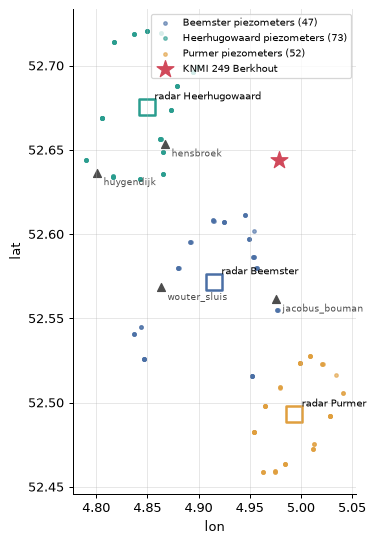

In [2]:
where = stresses.positions().dropna(subset=["polder", "lat"])
fig, ax = plt.subplots(figsize=(7, 7))
for (polder, group), colour in zip(where[where["polder"].isin(radar.POLDERS)].groupby("polder"),
                                   ["#4a6fa5", "#2a9d8f", "#e09f3e"]):
    ax.scatter(group["lon"], group["lat"], s=8, color=colour, alpha=0.6, label=f"{polder} piezometers ({len(group)})")
    lat, lon = POINTS[polder]
    ax.scatter(lon, lat, s=160, marker="s", facecolor="none", edgecolor=colour, lw=2)
    ax.annotate(f"radar {polder}", (lon, lat), xytext=(6, 6), textcoords="offset points", fontsize=8)
for name, (_, _, lat, lon) in stresses.GEMALEN.items():
    if lat is not None:
        ax.scatter(lon, lat, marker="^", color="0.3", s=40)
        ax.annotate(name, (lon, lat), xytext=(5, -10), textcoords="offset points", fontsize=7, color="0.3")
ax.scatter(4.979, 52.644, marker="*", s=200, color="#d1495b", label="KNMI 249 Berkhout")
ax.set_xlabel("lon"); ax.set_ylabel("lat"); ax.set_aspect(1 / np.cos(np.radians(52.6)))
ax.legend(fontsize=8, loc="upper right")
plt.show()

## Fetch (once)

This downloads 2020–2026: seven zips, about 5 GB. It extracts the three pixels and deletes each zip.
It takes 10–20 minutes. The result is cached in `pastas/data/forcing/local/radar_<polder>.csv`, so leave `FETCH = False` to use the cache.

In [3]:
FETCH = False
if FETCH or not all((radar.CACHE / f"radar_{p.lower()}.csv").exists() for p in radar.POLDERS):
    radar.update(list(range(2020, 2027)))
RADAR = pd.DataFrame({p: radar.load(p) for p in radar.POLDERS})
RADAR.describe().round(2)

,Beemster,Purmer,Heerhugowaard
count,2484.00,2484.00,2484.00
mean,2.67,2.63,2.63
std,5.34,5.28,5.21
min,0.00,0.00,0.00
25%,0.00,0.00,0.00
50%,0.11,0.10,0.11
75%,3.02,3.06,2.89
max,60.27,65.32,49.03


## Radar against Berkhout

Berkhout is KNMI 249 daily `RH`, 00–24 UT. To compare like with like, the radar's 08–08 UT days are moved one day back, as the models
do, and the comparison is also made on monthly sums, where the day boundary no longer matters.

In [4]:
berkhout, _ = data.load_forcing()
berkhout = (berkhout * 1000).rename("berkhout")
shifted = RADAR.copy()
shifted.index = shifted.index - pd.Timedelta(days=1)
both = shifted.join(berkhout, how="inner").dropna()
rows = []
for polder in radar.POLDERS:
    monthly = both[[polder, "berkhout"]].resample("MS").sum()
    rows.append({"polder": polder, "days": len(both), "radar mm/yr": round(365.25 * both[polder].mean()),
                 "Berkhout mm/yr": round(365.25 * both["berkhout"].mean()),
                 "r daily": round(both[polder].corr(both["berkhout"]), 2),
                 "r monthly": round(monthly[polder].corr(monthly["berkhout"]), 2),
                 "wet days radar (>1 mm)": int((both[polder] > 1).sum()),
                 "wet days Berkhout": int((both["berkhout"] > 1).sum()),
                 "days |diff| > 10 mm": int(((both[polder] - both["berkhout"]).abs() > 10).sum()),
                 "max radar": both[polder].max(), "max Berkhout": both["berkhout"].max()})
pd.DataFrame(rows)

,polder,days,radar mm/yr,Berkhout mm/yr,r daily,r monthly,wet days radar (>1 mm),wet days Berkhout,days |diff| > 10 mm,max radar,max Berkhout
0,Beemster,2484,976,888,0.74,0.97,910,887,69,60.27,45.7
1,Purmer,2484,959,888,0.69,0.97,910,887,75,65.32,45.7
2,Heerhugowaard,2484,960,888,0.75,0.97,906,887,70,49.03,45.7


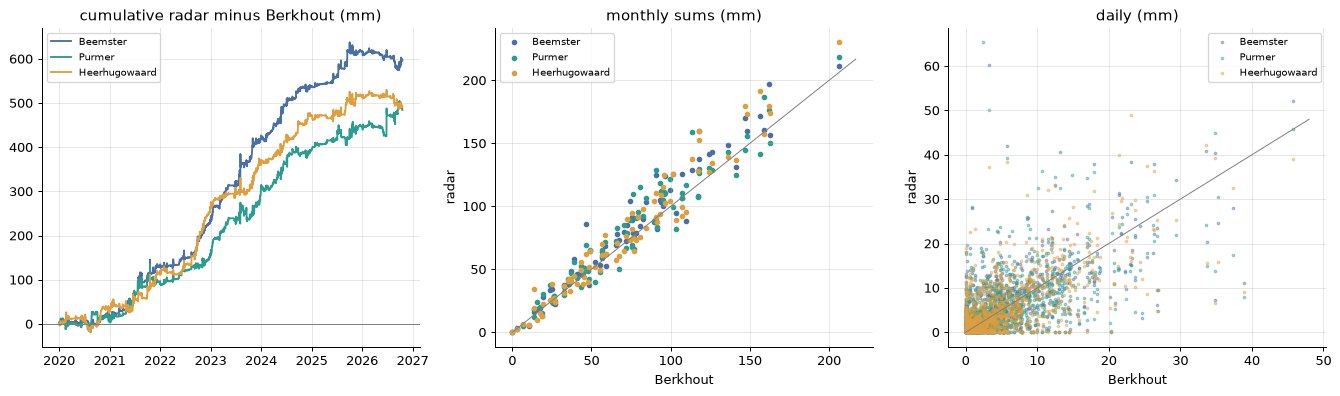

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for polder, colour in zip(radar.POLDERS, ["#4a6fa5", "#2a9d8f", "#e09f3e"]):
    axes[0].plot(both.index, both[polder].cumsum() - both["berkhout"].cumsum(), color=colour, label=polder)
    monthly = both[[polder, "berkhout"]].resample("MS").sum()
    axes[1].scatter(monthly["berkhout"], monthly[polder], s=12, color=colour, label=polder)
    axes[2].scatter(both["berkhout"], both[polder], s=4, alpha=0.4, color=colour, label=polder)
axes[0].set_title("cumulative radar minus Berkhout (mm)"); axes[0].axhline(0, color="0.5", lw=0.8)
for ax, title in zip(axes[1:], ["monthly sums (mm)", "daily (mm)"]):
    top = ax.get_xlim()[1]
    ax.plot([0, top], [0, top], color="0.5", lw=0.8)
    ax.set_xlabel("Berkhout"); ax.set_ylabel("radar"); ax.set_title(title)
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Does Pastas get better?

The full test ran on the 89 validated series (`research/accepted/run_variants.py --groups radar,radar+wl1+baro`).
* The `radar` variant replaces Berkhout precipitation with the polder's radar pixel over the radar years. Before 2020, during the warm-up, Berkhout is used.
* Evaporation stays Berkhout.
* Everything else is the same as the pipeline: the same model types, checks, and selection.

The table shows the accepted models per variant (one shared set, without the extremes), and the per-series fit change against Berkhout.
The result files are in `research/accepted/results/`.

In [6]:
results = PASTAS / "research" / "accepted" / "results"
scenarios = pd.read_csv(results / "gemaal_scenarios.csv")
scenarios[scenarios["scenario"].isin(["baseline", "radar", "wl1+baro", "radar+wl1+baro", "series"])]

,scenario,passed,gained,lost,p,Purmer_upper,Purmer_lower,Purmer_passed,Purmer_r2_holdout_median,Beemster_upper,Beemster_lower,Beemster_passed,Beemster_r2_holdout_median
0,baseline,35,0.0,0.0,1.0000,8,12,20,0.398,3,11,14,0.444
1,wl1+baro,55,20.0,0.0,0.0000,15,18,33,0.419,7,14,21,0.352
12,radar,40,5.0,0.0,0.0625,10,13,23,0.414,3,13,16,0.483
13,radar+wl1+baro,56,21.0,0.0,0.0000,18,16,34,0.450,7,14,21,0.466
14,series,89,NaN,NaN,NaN,26,22,48,NaN,19,21,40,NaN


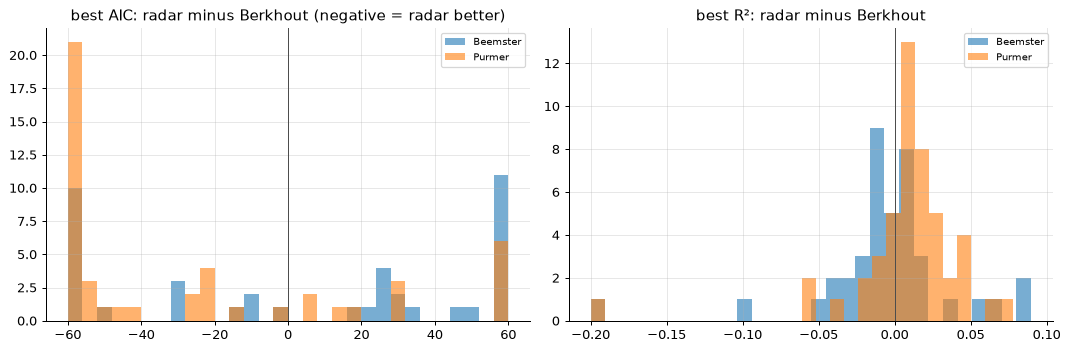

,series,radar_better,berkhout_better,median_d_aic,median_d_r2,median_d_r2_holdout
polder,,,,,,
Beemster,40,17,22,23.063,-0.004,0.026
Purmer,48,34,13,-50.986,0.011,0.033


In [7]:
fits = pd.read_csv(results / "radar_fits.csv")
summary = fits.groupby("polder").agg(series=("meetreeks_id", "size"),
                                     radar_better=("d_aic", lambda d: int((d < -2).sum())),
                                     berkhout_better=("d_aic", lambda d: int((d > 2).sum())),
                                     median_d_aic=("d_aic", "median"), median_d_r2=("d_r2", "median"),
                                     median_d_r2_holdout=("d_r2_holdout", "median")).round(3)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for polder, group in fits.groupby("polder"):
    axes[0].hist(group["d_aic"].clip(-60, 60), bins=30, alpha=0.6, label=polder)
    axes[1].hist(group["d_r2"].clip(-0.2, 0.2), bins=30, alpha=0.6, label=polder)
axes[0].set_title("best AIC: radar minus Berkhout (negative = radar better)")
axes[1].set_title("best R²: radar minus Berkhout")
for ax in axes:
    ax.axvline(0, color="0.3", lw=0.8); ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
summary